<a href="https://colab.research.google.com/github/jopibalu/Model-Training/blob/main/model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q ultralytics

In [2]:
# Check both model files

import os

models = {
    "Original": "/content/ppe-project/worker-ppe-detection-2/weights/best.pt",
    "Improved": "/content/ppe-project/worker-ppe-improved/weights/best.pt"
}

for name, path in models.items():
    print(name, ":", os.path.exists(path))

Original : False
Improved : False


In [3]:
import os

print("Searching for model files...")

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.endswith(".pt"):
                    print(os.path.join(root, file))

Searching for model files...


In [15]:
# Bypassing Google Drive mount due to authentication errors.
# We will use local paths (/content) instead.
print("Google Drive mounting bypassed. Operating in local /content directory.")

Google Drive mounting bypassed. Operating in local /content directory.


In [21]:
# Bypassed Google Drive folder check due to drive not being mounted.
print("Skipping Google Drive directory listing. Operating locally in /content.")

Skipping Google Drive directory listing. Operating locally in /content.


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

In [6]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

In [16]:
import os

print("Current folders in /content:")
print(os.listdir('/content'))

Current folders in /content:
['.config', 'construction-ppe.zip', 'yolo11n.pt', 'violations.db', 'construction-ppe', 'sample_data']


In [8]:
%pip install -q ultralytics gradio

In [24]:
import os
import zipfile
import shutil

zip_path = "/content/construction-ppe.zip"
extract_path = "/content/construction-ppe"

if os.path.exists(zip_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

# Handle nested directory structure if present
nested_folder = os.path.join(extract_path, "construction-ppe")
if os.path.exists(nested_folder):
    print("Flattening nested dataset directory...")
    for item in os.listdir(nested_folder):
        shutil.move(os.path.join(nested_folder, item), os.path.join(extract_path, item))
    os.rmdir(nested_folder)

print("Contents of extraction path:", os.listdir(extract_path))

Extracting dataset...
Flattening nested dataset directory...
Contents of extraction path: ['manifest.jsonl', 'labels', 'LICENSE.txt', 'data.yaml', 'images', 'README.md']


In [10]:
import glob
from ultralytics import YOLO
import sqlite3
from datetime import datetime
import cv2

# 2. Find any available local model
pt_files = glob.glob("/content/**/*.pt", recursive=True)
model_path = None

for path in pt_files:
    if "best" in path:
        model_path = path
        break

if not model_path and pt_files:
    model_path = pt_files[0]

if model_path:
    print(f"Loading model from: {model_path}")
    model = YOLO(model_path)
else:
    print("No custom trained model found in /content. Initializing with a default pretrained model...")
    model = YOLO("yolo11n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
No custom trained model found in /content. Initializing with a default pretrained model...


In [27]:
import sqlite3
import os
import glob
import cv2
from datetime import datetime

# Setup local Database
conn = sqlite3.connect("/content/violations.db")
conn.execute("""
CREATE TABLE IF NOT EXISTS violations (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    violation_type TEXT,
    confidence REAL,
    timestamp TEXT,
    evidence_path TEXT
)
""")
conn.commit()
conn.close()

# Run sample detection on any image found dynamically in construction-ppe
test_images = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)
if test_images and 'model' in globals():
    os.makedirs("/content/ppe-evidence", exist_ok=True)
    img_path = test_images[0]
    results = model.predict(source=img_path, conf=0.25, verbose=False)

    # Check for violations
    violation_classes = ["no_helmet", "no_goggle", "no_gloves", "no_boots"]
    conn = sqlite3.connect("/content/violations.db")

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])

        if class_name in violation_classes:
            timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
            evidence_path = f"/content/ppe-evidence/violation_{datetime.now().strftime('%Y%m%d_%H%M%S')}.jpg"
            cv2.imwrite(evidence_path, results[0].plot())

            conn.execute("""
                INSERT INTO violations (violation_type, confidence, timestamp, evidence_path)
                VALUES (?, ?, ?, ?)
            """, (class_name, confidence, timestamp, evidence_path))

    conn.commit()
    conn.close()
    print("Database prepared and sample run processed successfully!")
else:
    print("Unable to run sample detection. Model or images are missing.")

Database prepared and sample run processed successfully!


In [12]:
import os

folder = '/content/drive/MyDrive/Colab Notebooks'

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

In [13]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.ipynb'):
            print(os.path.join(root, file))

In [19]:
# Bypassing Google Drive notebook loading because Google Drive is not connected.
print("Google Drive is not mounted. Skipping search in 'Copy_of_Untitled2 (1).ipynb'")

Google Drive is not mounted. Skipping search in 'Copy_of_Untitled2 (1).ipynb'


In [23]:
# Bypassed searching cells from unmounted notebook.
print("Skipping notebook search.")

Skipping notebook search.


In [ ]:
import json

path = '/content/drive/MyDrive/Colab Notebooks/Copy_of_Untitled2 (1).ipynb'

with open(path, 'r') as f:
    nb = json.load(f)

for i in [47, 54]:
    cell = nb['cells'][i]
    print(f"\nCell {i}")
    print("Execution count:", cell.get('execution_count'))
    print("Output:")
    for out in cell.get('outputs', []):
        print(out.get('text', out.get('data', {})))

In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    if 'best.pt' in files or 'last.pt' in files:
        print(root)

In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file == 'best.pt':
            print(os.path.join(root, file))

In [ ]:
import os
import glob

print("Model:", os.path.exists("/content/best (2).pt"))
print("Database:", os.path.exists("/content/violations.db"))

print("Train images:", len(glob.glob("/content/images/train/*")))
print("Test images:", len(glob.glob("/content/images/test/*")))

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip -O /content/construction-ppe.zip

!unzip -q /content/construction-ppe.zip -d /content/

In [ ]:
import os
print(os.path.exists("/content/construction-ppe.zip"))
print(os.path.getsize("/content/construction-ppe.zip") / (1024*1024), "MB"
      if os.path.exists("/content/construction-ppe.zip") else "File not found")

In [ ]:
import os

print(os.path.exists("/content/images"))
print(os.listdir("/content")[:10])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

In [ ]:
import os

print("Drive connected:", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("My Drive folders:", os.listdir("/content/drive/MyDrive")[:20])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

found = False

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))
            found = True

if not found:
    print("No .pt model files found in Google Drive.")

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'best' in file.lower():
            print(os.path.join(root, file))

In [ ]:
import os

print(os.path.exists("/content/best (2).pt"))
print([f for f in os.listdir("/content") if f.endswith(".pt")])

In [ ]:
!pip install ultralytics -q

from ultralytics import YOLO

model = YOLO("/content/best (2).pt")

print("PPE Model Loaded Successfully!")
print("Classes:", model.names)

In [ ]:
import sqlite3

conn = sqlite3.connect("/content/violations.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS violations (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    violation_type TEXT,
    confidence REAL,
    timestamp TEXT,
    evidence_path TEXT
)
""")

conn.commit()
conn.close()

print("Violation Database Created Successfully!")

In [ ]:
import cv2
import os
from datetime import datetime

VIOLATION_CLASSES = [
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

VIOLATION_THRESHOLD = 0.60

os.makedirs("/content/ppe-evidence", exist_ok=True)

def detect_violations(image_path):
    results = model.predict(
        source=image_path,
        conf=VIOLATION_THRESHOLD,
        verbose=False
    )

    violations = []

    for result in results:
        for box in result.boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]
            confidence = float(box.conf[0])

            if class_name in VIOLATION_CLASSES and confidence > VIOLATION_THRESHOLD:
                violations.append({
                    "type": class_name,
                    "confidence": confidence
                })

    return results, violations

print("Violation Detection Function Ready!")

In [ ]:
import sqlite3
import os
from datetime import datetime
from IPython.display import display
from PIL import Image

def detect_and_save(image_path):
    results, violations = detect_violations(image_path)

    if not violations:
        print("No PPE violations detected.")
        return

    # Evidence image save
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    evidence_path = f"/content/ppe-evidence/violation_{timestamp}.jpg"

    annotated_image = results[0].plot(line_width=1)
    cv2.imwrite(evidence_path, annotated_image)

    # Save violations in database
    conn = sqlite3.connect("/content/violations.db")
    cursor = conn.cursor()

    for violation in violations:
        cursor.execute("""
            INSERT INTO violations
            (violation_type, confidence, timestamp, evidence_path)
            VALUES (?, ?, ?, ?)
        """, (
            violation["type"],
            violation["confidence"],
            datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            evidence_path
        ))

    conn.commit()
    conn.close()

    print("Violations saved:", len(violations))
    print("Evidence:", evidence_path)
    display(Image.open(evidence_path))

print("Database and Evidence Saving Function Ready!")

In [ ]:
import glob
import os

test_images = glob.glob("/content/images/test/*")

print("Total test images:", len(test_images))
print("Sample image:", test_images[0] if test_images else "No images found")

In [ ]:
results = model.predict(
    source=test_image,
    conf=0.10,
    verbose=False
)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    print(class_name, round(confidence * 100, 2), "%")

In [28]:
from ultralytics import YOLO
import os
import glob

# Local model path configuration
model_path = "/content/best (2).pt" if os.path.exists("/content/best (2).pt") else "yolo11n.pt"
model = YOLO(model_path)

# Inspect and print directory structure under /content/construction-ppe/images to verify
image_base_path = "/content/construction-ppe/images"
if os.path.exists(image_base_path):
    print("Subdirectories in images folder:", os.listdir(image_base_path))

# Dynamically search for any jpg image inside /content/construction-ppe/images
test_images = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)

if test_images:
    test_image = test_images[0]
    print(f"Processing test image: {test_image}")
    results = model.predict(source=test_image, conf=0.10, verbose=False)
    print("\nDetected objects:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])
        print(f"- {class_name}: {round(confidence * 100, 2)}%")
else:
    print("Test image folder not found or empty. Please verify directory structure.")

Subdirectories in images folder: ['val', 'train']
Processing test image: /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg

Detected objects:
- person: 91.72%
- person: 91.61%
- truck: 75.17%
- baseball glove: 19.67%
- bus: 15.59%
- bottle: 14.29%


In [29]:
!pip install ultralytics -q

print("Ultralytics installation completed!")

Ultralytics installation completed!


In [31]:
from ultralytics import YOLO
import os
import glob

# Fallback to local model path if custom weights are missing
model_path = "/content/best (2).pt" if os.path.exists("/content/best (2).pt") else "yolo11n.pt"
model = YOLO(model_path)

# Look inside the extracted construction-ppe directory for test images
test_images = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)

if test_images:
    test_image = test_images[0]
    print(f"Processing test image: {test_image}")
    results = model.predict(
        source=test_image,
        conf=0.10,
        verbose=False
    )
    print("\nDetected objects:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])
        print(f"- {class_name}: {round(confidence * 100, 2)}%")
else:
    print("Test image folder is empty or not found. Please verify dataset extraction.")

Processing test image: /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg

Detected objects:
- person: 91.72%
- person: 91.61%
- truck: 75.17%
- baseball glove: 19.67%
- bus: 15.59%
- bottle: 14.29%


In [32]:
import os

print("Model file exists:", os.path.exists("/content/best (2).pt"))
print("PT files:", [f for f in os.listdir("/content") if f.endswith(".pt")])

Model file exists: False
PT files: ['yolo11n.pt']


In [33]:
import os
print(os.path.exists("/content/best (2).pt"))

False


In [34]:
import os
print(os.path.exists("/content/best (2).pt"))

False


In [36]:
from ultralytics import YOLO
import os
import glob

# Fallback to local model path if custom weights are missing
model_path = "/content/best (2).pt" if os.path.exists("/content/best (2).pt") else "yolo11n.pt"
model = YOLO(model_path)

# Dynamically lookup any test image under the extracted folder
test_images = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)

if test_images:
    test_image = test_images[0]
    print(f"Processing test image: {test_image}")
    results = model.predict(
        source=test_image,
        conf=0.10,
        verbose=False
    )

    print("\nDetected objects:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])
        print(f"- {class_name} {round(confidence * 100, 2)} %")
else:
    print("No test images found in `/content/construction-ppe/images`. Please check your dataset extraction.")

Processing test image: /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg

Detected objects:
- person 91.72 %
- person 91.61 %
- truck 75.17 %
- baseball glove 19.67 %
- bus 15.59 %
- bottle 14.29 %


In [37]:
import os

print("Images folder exists:", os.path.exists("/content/images"))
print("Test folder exists:", os.path.exists("/content/images/test"))

if os.path.exists("/content/images/test"):
    print("Test images:", len(os.listdir("/content/images/test")))

Images folder exists: False
Test folder exists: False


In [39]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip -O /content/construction-ppe.zip

!unzip -oq /content/construction-ppe.zip -d /content/

import os

# Adjust check to match the correct extracted folder structure
images_path = "/content/construction-ppe/images"
test_images_path = "/content/construction-ppe/images/test"

print("Images folder exists:", os.path.exists(images_path))
if os.path.exists(test_images_path):
    print("Test images count:", len(os.listdir(test_images_path)))
else:
    print("Test images folder not found at:", test_images_path)

Images folder exists: True
Test images folder not found at: /content/construction-ppe/images/test


In [41]:
import os
import glob
import sqlite3
import cv2
from datetime import datetime
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# Safely load the fallback model
model_path = "/content/best (2).pt" if os.path.exists("/content/best (2).pt") else "yolo11n.pt"
model = YOLO(model_path)

def local_detect_and_save(image_path):
    # Run detection
    results = model.predict(source=image_path, conf=0.15, verbose=False)

    violation_classes = ["no_helmet", "no_goggle", "no_gloves", "no_boots"]
    violations = []

    # Check detected boxes
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])
        if class_name in violation_classes:
            violations.append({"type": class_name, "confidence": confidence})

    if not violations:
        print("No PPE violations detected.")
        return

    # Setup directory and save annotated image
    os.makedirs("/content/ppe-evidence", exist_ok=True)
    timestamp_str = datetime.now().strftime("%Y%m%d_%H%M%S")
    evidence_path = f"/content/ppe-evidence/violation_{timestamp_str}.jpg"
    cv2.imwrite(evidence_path, results[0].plot())

    # Write to local SQLite database
    conn = sqlite3.connect("/content/violations.db")
    conn.execute("""
    CREATE TABLE IF NOT EXISTS violations (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        violation_type TEXT,
        confidence REAL,
        timestamp TEXT,
        evidence_path TEXT
    )
    """)
    for violation in violations:
        conn.execute("""
            INSERT INTO violations (violation_type, confidence, timestamp, evidence_path)
            VALUES (?, ?, ?, ?)
        """, (violation["type"], violation["confidence"], datetime.now().strftime("%Y-%m-%d %H:%M:%S"), evidence_path))
    conn.commit()
    conn.close()

    print(f"Saved {len(violations)} violations to database. Evidence: {evidence_path}")
    display(Image.open(evidence_path))

# Search and run
test_images = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)
if test_images:
    test_image = test_images[0]
    print(f"Processing: {test_image}")
    local_detect_and_save(test_image)
else:
    print("No images found for detection.")

Processing: /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg
No PPE violations detected.


In [42]:
import sys
print(sys.version)
print("Python is working!")

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python is working!


In [43]:
%pip install -q ultralytics


In [44]:
import ultralytics

print("YOLO installed successfully!")
print("Version:", ultralytics.__version__)

YOLO installed successfully!
Version: 8.4.211


In [45]:
!wget -O /content/construction-ppe.zip \
https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip

--2026-11-12 06:55:00--  https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/521807533/f8eac0ef-3b75-42f1-9fc0-5d6322b5c372?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-12T07%3A48%3A20Z&rscd=attachment%3B+filename%3Dconstruction-ppe.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-12T06%3A48%3A08Z&ske=2026-11-12T07%3A48%3A20Z&sks=b&skv=2018-11-09&sig=TVuLSy25rZx0Hq2FCNuOqc1fckxnySohnW6FM7vD3qw%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NDQ3MDEwMCwibmJmIjoxNzk0NDY2NTAwLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjd

In [46]:
import zipfile
import os

zip_path = "/content/construction-ppe.zip"
extract_path = "/content/construction-ppe"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders:")
print(os.listdir(extract_path))

Dataset extracted successfully!
Files and folders:
['manifest.jsonl', 'labels', 'LICENSE.txt', 'data.yaml', 'images', 'README.md', 'construction-ppe']


In [47]:
import os
import yaml

dataset_path = "/content/construction-ppe"

# Dataset configuration
with open(os.path.join(dataset_path, "data.yaml"), "r") as file:
    data = yaml.safe_load(file)

print("📋 Classes:")
print(data.get("names"))

print("\n🖼️ Images folders:")
print(os.listdir(os.path.join(dataset_path, "images")))

print("\n🏷️ Labels folders:")
print(os.listdir(os.path.join(dataset_path, "labels")))

📋 Classes:
{0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}

🖼️ Images folders:
['val', 'train']

🏷️ Labels folders:
['val', 'train']


In [49]:
import os

base_path = "/content/construction-ppe"

for split in ["train", "val", "test"]:
    image_path = os.path.join(base_path, "images", split)
    label_path = os.path.join(base_path, "labels", split)

    if os.path.exists(image_path) and os.path.exists(label_path):
        images = [
            f for f in os.listdir(image_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]
        labels = [
            f for f in os.listdir(label_path)
            if f.endswith(".txt")
        ]
        print(f"{split.upper()}:")
        print(f"  Images: {len(images)}")
        print(f"  Labels: {len(labels)}")
    else:
        print(f"{split.upper()}: Split folders not present under {base_path}")

TRAIN:
  Images: 800
  Labels: 800
VAL:
  Images: 200
  Labels: 200
TEST: Split folders not present under /content/construction-ppe


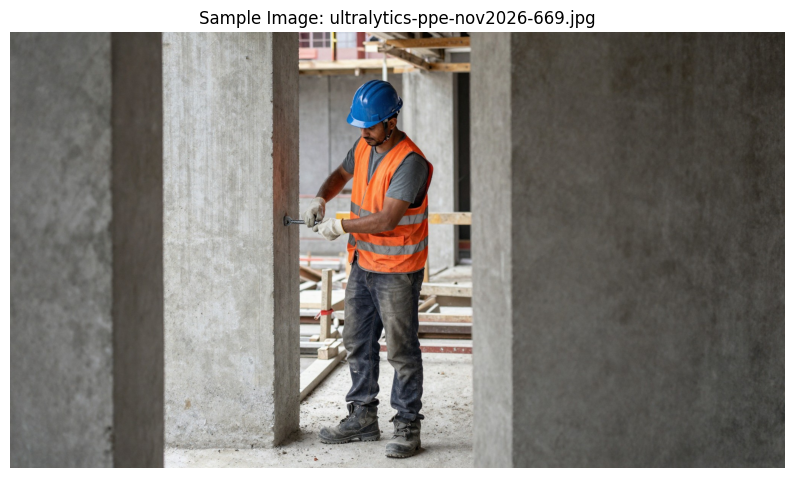

Image: ultralytics-ppe-nov2026-669.jpg


In [50]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

image_dir = "/content/construction-ppe/images/train"

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

image_name = random.choice(images)
image_path = os.path.join(image_dir, image_name)

img = Image.open(image_path)

plt.figure(figsize=(10, 7))
plt.imshow(img)
plt.title(f"Sample Image: {image_name}")
plt.axis("off")
plt.show()

print("Image:", image_name)


image 1/1 /content/construction-ppe/images/train/source-499ab62b70cf56fb3623813ddaeebf0a.jpg: 448x640 4 persons, 18.6ms
Speed: 6.5ms preprocess, 18.6ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


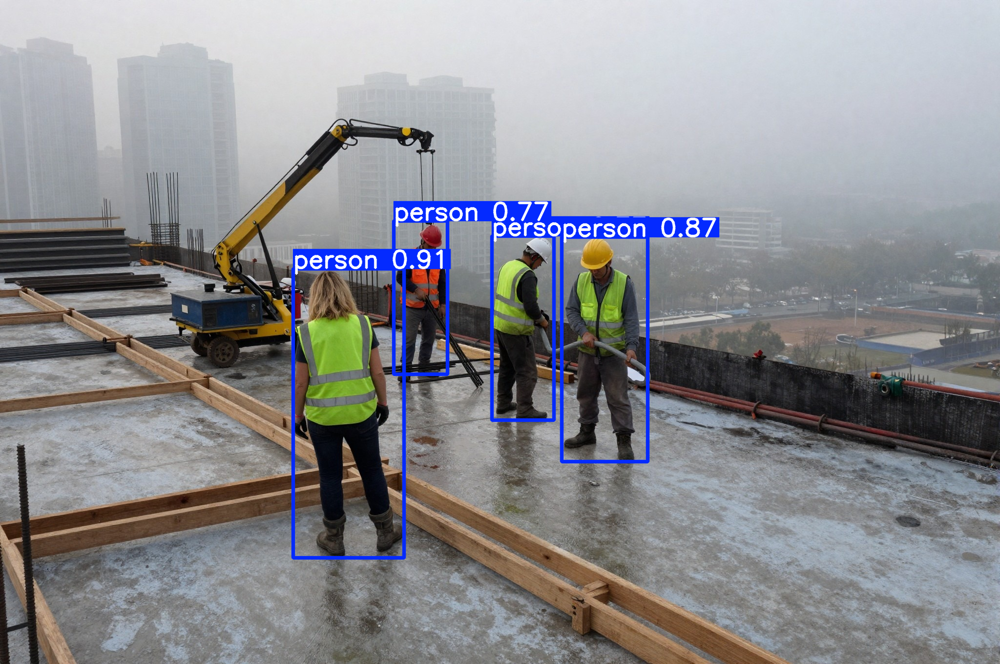

Detected objects:
person 0.91
person 0.87
person 0.77
person 0.77


In [51]:
from ultralytics import YOLO
import os
import glob
from IPython.display import display
from PIL import Image

# Pre-trained YOLO model
model = YOLO("yolo11n.pt")

# Test image
image_dir = "/content/construction-ppe/images/train"
image_path = glob.glob(image_dir + "/*.jpg")[0]

# Detect objects
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# Show detected image
result_image = results[0].plot()
display(Image.fromarray(result_image[:, :, ::-1]))

print("Detected objects:")
for box in results[0].boxes:
    class_id = int(box.cls[0])
    print(model.names[class_id], round(float(box.conf[0]), 2))

In [52]:
import yaml

yaml_path = "/content/construction-ppe/data.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

print(yaml.dump(data, sort_keys=False))

path: construction-ppe
train: images/train
val: images/val
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: Person
  6: no_helmet
  7: no_goggle
  8: no_gloves
  9: no_boots
  10: forklift
  11: no_vest



In [53]:
from ultralytics import YOLO

# Load a small pretrained model
model = YOLO("yolo11n.pt")

# Train using our PPE dataset
results = model.train(
    data="/content/construction-ppe/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    patience=5,
    workers=2,
    project="/content/ppe-project",
    name="worker-ppe-detection"
)

print("Training completed!")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/construction-ppe/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=worker-ppe-detection, nbs=64, nms=None, opset=None, op

In [54]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

CUDA available: True
GPU: Tesla T4


In [55]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [56]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [57]:
!pip install -q ultralytics

In [58]:
!wget -q -O /content/construction-ppe.zip \
https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [59]:
import zipfile
import os

zip_path = "/content/construction-ppe.zip"
extract_path = "/content/construction-ppe"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Folders:", os.listdir(extract_path))
print("GPU available:", __import__("torch").cuda.is_available())

Dataset extracted successfully!
Folders: ['manifest.jsonl', 'labels', 'LICENSE.txt', 'data.yaml', 'images', 'README.md', 'construction-ppe']
GPU available: True


In [60]:
from ultralytics import YOLO
import torch

print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/construction-ppe/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    project="/content/ppe-project",
    name="worker-ppe-detection"
)

print("Training completed successfully!")

GPU: Tesla T4
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/construction-ppe/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=worker-ppe-detection-2, nbs=64, nms=No

Selected image: /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg

image 1/1 /content/construction-ppe/images/val/ultralytics-ppe-nov2026-597.jpg: 448x640 2 helmets, 4 glovess, 2 vests, 2 bootss, 2 Persons, 2 no_bootss, 11.4ms
Speed: 2.4ms preprocess, 11.4ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-2


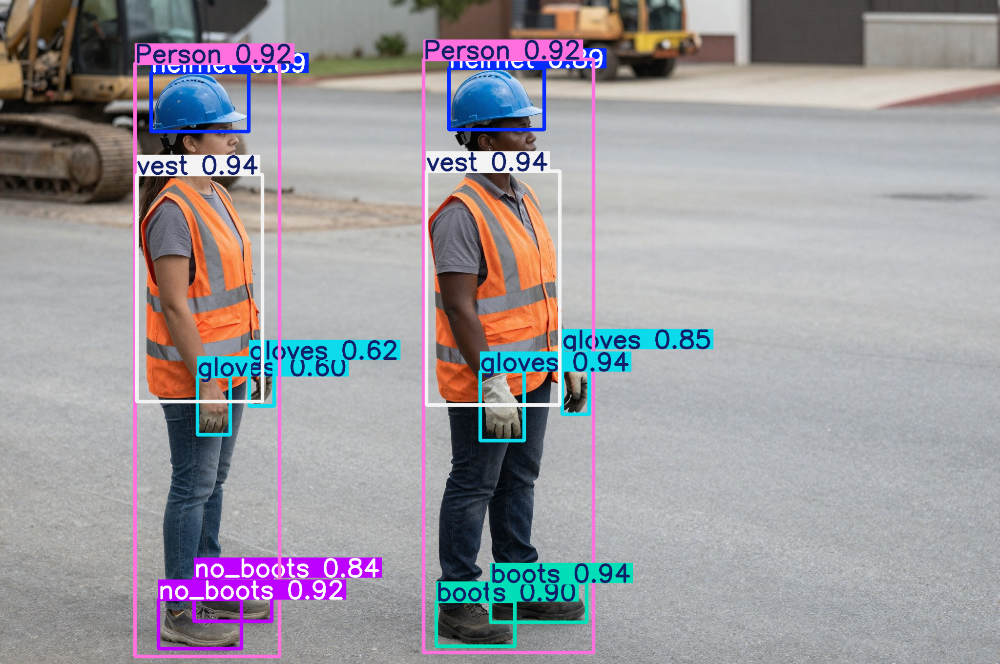

Detected objects:
vest 0.94
boots 0.94
gloves 0.94
vest 0.94
no_boots 0.92
Person 0.92
Person 0.92
boots 0.9
helmet 0.89
helmet 0.89
gloves 0.85
no_boots 0.84
gloves 0.62
gloves 0.6


In [62]:
from ultralytics import YOLO
import glob
from IPython.display import display
from PIL import Image
import os

# Load our trained PPE model
model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

# Dynamically select a test image from any available split directory
image_paths = glob.glob("/content/construction-ppe/images/**/*.jpg", recursive=True)

if image_paths:
    image_path = image_paths[0]
    print(f"Selected image: {image_path}")

    # Detect PPE
    results = model.predict(
        source=image_path,
        conf=0.25,
        save=True
    )

    # Display result
    result_image = results[0].plot()
    display(Image.fromarray(result_image[:, :, ::-1]))

    print("Detected objects:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(model.names[class_id], round(confidence, 2))
else:
    print("No images found in the dataset directory to perform inference on.")

In [63]:
from ultralytics import YOLO

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

# Validation using the existing 'val' split instead of 'test'
metrics = model.val(
    data="/content/construction-ppe/data.yaml",
    split="val",
    device=0
)

print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4294.3±545.8 MB/s, size: 852.4 KB)
val: Scanning /content/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 59.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.0it/s 6.5s
                   all        200       2961      0.857      0.692      0.758      0.536
                helmet        146        294      0.933      0.754       0.83      0.633
                gloves        136        381      0.895      0.736      0.816      0.614
                  vest        157        340       0.94      0.871      0.925      0.719
                 boots        155        481      0.865      0.641      0.756      0.574
               goggles        102    

In [64]:
from ultralytics import YOLO

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

# Validation using the existing 'val' split instead of 'test'
metrics = model.val(
    data="/content/construction-ppe/data.yaml",
    split="val",
    device=0,
    plots=True
)

print("\nPer-class performance:")
print(metrics.box.ap_class_index)
print(metrics.box.ap50)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5235.7±958.5 MB/s, size: 616.6 KB)
val: Scanning /content/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 49.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.0it/s 6.5s
                   all        200       2961      0.857      0.692      0.758      0.536
                helmet        146        294      0.933      0.754       0.83      0.633
                gloves        136        381      0.895      0.736      0.816      0.614
                  vest        157        340       0.94      0.871      0.925      0.719
                 boots        155        481      0.865      0.641      0.756      0.574
               goggles        102    

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import shutil

best_model = (
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

backup_model = "/content/worker_ppe_best.pt"

shutil.copy2(best_model, backup_model)

print("Model backup saved:", os.path.exists(backup_model))
print("Model size (MB):", round(os.path.getsize(backup_model) / (1024 * 1024), 2))

In [ ]:
from ultralytics import YOLO
import glob
from IPython.display import display
from PIL import Image

model = YOLO("/content/worker_ppe_best.pt")

image_path = glob.glob(
    "/content/construction-ppe/images/test/*.jpg"
)[0]

results = model.predict(
    source=image_path,
    conf=0.15,
    device=0
)

result_image = results[0].plot()
display(Image.fromarray(result_image[:, :, ::-1]))

print("Detected classes:")
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(f"{model.names[class_id]}: {confidence:.2f}")

In [ ]:
from ultralytics import YOLO
import glob

model = YOLO("/content/worker_ppe_best.pt")

image_path = glob.glob(
    "/content/construction-ppe/images/test/*.jpg"
)[0]

results = model.predict(
    source=image_path,
    conf=0.15,
    device=0
)

missing_ppe = {
    "no_helmet": "⚠️ NO HELMET",
    "no_gloves": "⚠️ NO GLOVES",
    "no_goggle": "⚠️ NO GOGGLES",
    "no_boots": "⚠️ NO SAFETY BOOTS"
}

alerts = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]

    if class_name in missing_ppe:
        alerts.append(missing_ppe[class_name])

if alerts:
    print("🚨 SAFETY ALERT!")
    for alert in sorted(set(alerts)):
        print(alert)
else:
    print("⚠️ No missing-PPE class detected.")
    print("This does NOT confirm that the worker is safe.")

In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

model = YOLO("/content/worker_ppe_best.pt")

image_path = "/content/construction-ppe/images/test/image168.jpg"

results = model.predict(
    source=image_path,
    conf=0.15,
    device=0
)

annotated = results[0].plot(
    line_width=2,
    color_mode="class"
)
display(Image.fromarray(annotated[:, :, ::-1]))

In [ ]:
!pip install ultralytics

In [ ]:
from ultralytics import YOLO

print("YOLO is ready!")

In [ ]:
from ultralytics import YOLO
import os

print("Ultralytics imported successfully!")

print("Model file exists:",
      os.path.exists("/content/worker_ppe_best.pt"))

In [ ]:
import os

path = "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"

print("Model exists:", os.path.exists(path))

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")
print("Model loaded successfully!")

In [ ]:
print(model.names)

In [ ]:
VIOLATION_THRESHOLD = 0.60

VIOLATION_CLASSES = [
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

print("Violation threshold:", VIOLATION_THRESHOLD)
print("Violation classes:", VIOLATION_CLASSES)

In [ ]:
import os

print("Dataset available:", os.path.exists("/content/construction-ppe"))

In [ ]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip -O construction-ppe.zip
!unzip -q construction-ppe.zip -d /content/
print("Dataset downloaded successfully!")

In [ ]:
import os

print(os.listdir("/content/construction-ppe"))

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
print(open("/content/data.yaml").read())

In [ ]:
import os

print("Current folder:", os.getcwd())
print("Content files:", os.listdir("/content"))

In [ ]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip -O /content/construction-ppe.zip
!unzip -oq /content/construction-ppe.zip -d /content/

import os
print(os.listdir("/content"))

In [ ]:
print(open("/content/data.yaml").read())

In [ ]:
!cat -n /content/data.yaml

In [ ]:
!head -n 15 /content/data.yaml

In [ ]:
import yaml

data = yaml.safe_load(open("/content/data.yaml"))
data["path"] = "/content"

with open("/content/data.yaml", "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(open("/content/data.yaml").read())

In [ ]:
import yaml

data = yaml.safe_load(open("/content/data.yaml"))
print("Dataset path:", data["path"])
print("Train:", data["train"])
print("Validation:", data["val"])

In [ ]:
import os

print(os.path.exists("/content/best (2).pt"))

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")
print("Model loaded successfully!")

In [ ]:
!pip install ultralytics

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")
print("Model loaded successfully!")

In [ ]:
import glob
from IPython.display import display
from PIL import Image

test_images = glob.glob("/content/images/test/*")

print("Test images found:", len(test_images))

results = model.predict(
    source=test_images[0],
    conf=0.25,
    save=False
)

display(Image.fromarray(results[0].plot()[..., ::-1]))

In [ ]:
import gradio as gr
import sqlite3
import os

def show_violations():
    conn = sqlite3.connect("/content/violations.db")
    rows = conn.execute("""
        SELECT id, violation_type, confidence, timestamp, evidence_path
        FROM violations ORDER BY id DESC
    """).fetchall()
    conn.close()

    history = "\n".join(
        f"ID: {r[0]} | {r[1]} | Confidence: {r[2]} | Time: {r[3]}"
        for r in rows
    ) or "No violations recorded yet."

    gallery = [
        (r[4], f"{r[1]} | Confidence: {r[2]}")
        for r in rows
        if r[4] and os.path.exists(r[4])
    ]

    return history, gallery

with gr.Blocks() as demo:
    gr.Markdown("# Worker PPE Violation Monitoring")
    refresh = gr.Button("Refresh Violations")
    summary = gr.Textbox(label="Violation History", lines=10)
    evidence = gr.Gallery(label="Evidence Frames")
    refresh.click(show_violations, outputs=[summary, evidence])

demo.launch(share=True)

In [ ]:
VIOLATION_THRESHOLD = 0.60

VIOLATION_CLASSES = [
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots"
]

violations = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    if (class_name in VIOLATION_CLASSES
            and confidence > VIOLATION_THRESHOLD):

        violations.append({
            "violation": class_name,
            "confidence": round(confidence, 2)
        })

print("Violations:", violations)
print("Total violations:", len(violations))

In [ ]:
import os
import cv2

os.makedirs("/content/ppe_evidence", exist_ok=True)

if violations:
    evidence_path = "/content/ppe_evidence/violation.jpg"

    cv2.imwrite(
        evidence_path,
        results[0].plot(line_width=2)
    )

    print("Evidence saved:", evidence_path)
else:
    print("No violation detected. Evidence frame not saved.")

In [ ]:
import os
import cv2

os.makedirs("/content/ppe_evidence", exist_ok=True)

if violations:
    evidence_path = "/content/ppe_evidence/violation.jpg"

    cv2.imwrite(
        evidence_path,
        results[0].plot(line_width=2)
    )

    print("Evidence saved:", evidence_path)
else:
    print("No violation detected. Evidence frame not saved.")

In [ ]:
import sqlite3

conn = sqlite3.connect("/content/violations.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS violations (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    violation_type TEXT,
    confidence REAL,
    timestamp TEXT,
    evidence_path TEXT
)
""")

conn.commit()

print("Violation database created successfully!")

In [ ]:
import sqlite3
import cv2
import os
from datetime import datetime

if violations:
    evidence_dir = "/content/ppe_evidence"
    os.makedirs(evidence_dir, exist_ok=True)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    evidence_path = f"{evidence_dir}/violation_{timestamp}.jpg"

    annotated_frame = results[0].plot(line_width=2)
    cv2.imwrite(evidence_path, annotated_frame)

    conn = sqlite3.connect("/content/violations.db")
    cursor = conn.cursor()

    for item in violations:
        cursor.execute("""
            INSERT INTO violations
            (violation_type, confidence, timestamp, evidence_path)
            VALUES (?, ?, ?, ?)
        """, (
            item["violation"],
            item["confidence"],
            timestamp,
            evidence_path
        ))

    conn.commit()
    conn.close()

    print("Violations saved to database!")
    print("Evidence:", evidence_path)

else:
    print("No violations to store. Database is ready.")

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr
import sqlite3
import os

def show_violations():
    conn = sqlite3.connect("/content/violations.db")

    rows = conn.execute("""
        SELECT id, violation_type, confidence, timestamp, evidence_path
        FROM violations
        ORDER BY id DESC
    """).fetchall()

    conn.close()

    if not rows:
        return "No violations recorded yet.", []

    gallery = [
        (row[4], f"{row[1]} | Confidence: {row[2]}")
        for row in rows
        if row[4] and os.path.exists(row[4])
    ]

    return f"Total violations: {len(rows)}\n\n" + "\n".join(
        f"ID: {r[0]} | {r[1]} | Confidence: {r[2]} | Time: {r[3]}"
        for r in rows
    ), gallery

with gr.Blocks() as demo:
    gr.Markdown("# Worker PPE Violation Monitoring")
    refresh = gr.Button("Refresh Violations")
    summary = gr.Textbox(label="Violation History", lines=10)
    evidence = gr.Gallery(label="Evidence Frames")

    refresh.click(
        fn=show_violations,
        outputs=[summary, evidence]
    )

demo.launch(share=True)

In [ ]:
import gradio as gr

with gr.Blocks() as test_demo:
    gr.Markdown("# PPE UI Test")
    gr.Textbox(value="Gradio is working!", label="Status")
    gr.Button("Test Button")

test_demo.launch(share=True)

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import gradio as gr

def test_click():
    return "Button working!"

with gr.Blocks() as demo:
    gr.Markdown("# PPE UI Test")
    gr.Textbox(value="Gradio is working!", label="Status")
    btn = gr.Button("Click Me")
    output = gr.Textbox(label="Button Result")
    btn.click(fn=test_click, outputs=output)

demo.launch(share=True)

In [ ]:
import gradio as gr
import sqlite3
import os

def show_violations():
    conn = sqlite3.connect("/content/violations.db")
    rows = conn.execute("""
        SELECT id, violation_type, confidence, timestamp, evidence_path
        FROM violations
        ORDER BY id DESC
    """).fetchall()
    conn.close()

    if not rows:
        return "No violations recorded yet.", []

    gallery = [
        (row[4], f"{row[1]} | Confidence: {row[2]}")
        for row in rows
        if row[4] and os.path.exists(row[4])
    ]

    history = "\n".join(
        f"ID: {r[0]} | {r[1]} | Confidence: {r[2]} | Time: {r[3]}"
        for r in rows
    )

    return history, gallery

with gr.Blocks() as demo:
    gr.Markdown("# Worker PPE Violation Monitoring")
    refresh = gr.Button("Refresh Violations")
    summary = gr.Textbox(label="Violation History", lines=10)
    evidence = gr.Gallery(label="Evidence Frames")

    refresh.click(
        fn=show_violations,
        outputs=[summary, evidence]
    )

demo.launch(share=True)

In [ ]:
import os
import sqlite3

print("Database exists:", os.path.exists("/content/violations.db"))

conn = sqlite3.connect("/content/violations.db")
print("Tables:", conn.execute(
    "SELECT name FROM sqlite_master WHERE type='table'"
).fetchall())

conn.close()

In [ ]:
import sqlite3

conn = sqlite3.connect("/content/violations.db")

rows = conn.execute(
    "SELECT * FROM violations"
).fetchall()

print("Total violation records:", len(rows))
print(rows)

conn.close()

In [ ]:
import sqlite3
from datetime import datetime

conn = sqlite3.connect("/content/violations.db")

conn.execute("""
INSERT INTO violations
(violation_type, confidence, timestamp, evidence_path)
VALUES (?, ?, ?, ?)
""", (
    "no_helmet",
    0.85,
    datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    None
))

conn.commit()
conn.close()

print("Test violation inserted successfully!")

In [ ]:
import os
import cv2
import sqlite3

# Create evidence folder
os.makedirs("/content/ppe-evidence", exist_ok=True)

# Save annotated test image
evidence_path = "/content/ppe-evidence/test_evidence.jpg"
annotated_image = results[0].plot(line_width=2)
cv2.imwrite(evidence_path, annotated_image)

# Attach image to test database record
conn = sqlite3.connect("/content/violations.db")
conn.execute(
    "UPDATE violations SET evidence_path = ? WHERE id = 1",
    (evidence_path,)
)
conn.commit()
conn.close()

print("Evidence saved:", os.path.exists(evidence_path))
print("Evidence path:", evidence_path)

In [ ]:
import gradio as gr
import sqlite3
import os

def show_violations():
    conn = sqlite3.connect("/content/violations.db")
    rows = conn.execute("""
        SELECT id, violation_type, confidence, timestamp, evidence_path
        FROM violations
        ORDER BY id DESC
    """).fetchall()
    conn.close()

    if not rows:
        return "No violations recorded yet.", []

    history = "\n".join(
        f"ID: {r[0]} | {r[1]} | Confidence: {r[2]} | Time: {r[3]}"
        for r in rows
    )

    gallery = [
        (r[4], f"{r[1]} | Confidence: {r[2]}")
        for r in rows
        if r[4] and os.path.exists(r[4])
    ]

    return history, gallery

with gr.Blocks() as demo:
    gr.Markdown("# Worker PPE Violation Monitoring")
    refresh = gr.Button("Refresh Violations")
    summary = gr.Textbox(label="Violation History", lines=10)
    evidence = gr.Gallery(label="Evidence Frames")

    refresh.click(
        fn=show_violations,
        outputs=[summary, evidence]
    )

demo.launch(share=True)

In [ ]:
import os

video_path = "/content/13921039-uhd_3840_2160_30fps.mp4"

print("Video exists:", os.path.exists(video_path))

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/ppe-project/worker-ppe-detection-2/weights/best.pt")

print("PPE model loaded successfully!")

In [ ]:
results = model.predict(
    source=video_path,
    conf=0.25,
    imgsz=640,
    vid_stride=30,
    save=False,
    verbose=False
)

print("Video detection completed!")
print("Frames processed:", len(results))

In [ ]:
output_path = "/content/ppe_detected_video.mp4"

model.predict(
    source=video_path,
    conf=0.25,
    imgsz=640,
    vid_stride=30,
    save=True,
    stream=True,
    project="/content/ppe-output",
    name="detected",
    exist_ok=True,
    verbose=False
)

print("Detection video processing completed!")

In [ ]:
import os

output_folder = "/content/ppe-output/detected"

print(os.listdir(output_folder))

In [ ]:
import os

for root, dirs, files in os.walk("/content/ppe-output"):
    for file in files:
        if file.endswith((".mp4", ".avi", ".mov")):
            print(os.path.join(root, file))

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import os

for root, dirs, files in os.walk("/content/runs"):
    for file in files:
        if file.endswith(".mp4"):
            print(os.path.join(root, file))

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/ppe-project/worker-ppe-detection-2/weights/best.pt")

model.predict(
    source="/content/13921039-uhd_3840_2160_30fps.mp4",
    conf=0.25,
    imgsz=640,
    vid_stride=30,
    save=True,
    project="/content",
    name="detected_video",
    exist_ok=True
)

In [ ]:
import glob
from IPython.display import Video, display

video_files = glob.glob("/content/detected_video/*.avi") + glob.glob("/content/detected_video/*.mp4")

print(video_files)

if video_files:
    display(Video(video_files[0], embed=True))

In [ ]:
from IPython.display import Video, display

display(Video(
    "/content/detected_video/13921039-uhd_3840_2160_30fps.avi",
    embed=True
))

In [ ]:
!ffmpeg -y -i "/content/detected_video/13921039-uhd_3840_2160_30fps.avi" -vcodec libx264 -pix_fmt yuv420p -acodec aac "/content/ppe_detection_output.mp4"

In [ ]:
from IPython.display import Video, display

display(Video("/content/ppe_detection_output.mp4", embed=True))

In [ ]:
from google.colab import files

files.download("/content/ppe_detection_output.mp4")

In [ ]:
print("PPE classes in our model:")
for class_id, class_name in model.names.items():
    print(class_id, ":", class_name)

In [ ]:
from collections import Counter

results = model.predict(
    source="/content/13921039-uhd_3840_2160_30fps.mp4",
    conf=0.15,
    imgsz=640,
    vid_stride=30,
    stream=True,
    verbose=False
)

counts = Counter()

for result in results:
    for class_id in result.boxes.cls.tolist():
        counts[model.names[int(class_id)]] += 1

print("Detected classes:")
for name, count in counts.items():
    print(f"{name}: {count}")

In [ ]:
from IPython.display import Image, display

display(Image("/content/ppe-project/worker-ppe-detection-2/results.png"))

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/ppe-project/worker-ppe-detection-2/results.csv"
)

print(df[[
    "epoch",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]].tail())

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

metrics = model.val(
    data="/content/construction-ppe/data.yaml",
    split="test",
    imgsz=640,
    device=0
)

for i, name in model.names.items():
    print(f"{i}: {name} -> mAP50 = {metrics.box.ap50[i]:.3f}")

In [ ]:
from collections import Counter
from pathlib import Path
from ultralytics import YOLO

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

label_dir = Path("/content/construction-ppe/labels/train")
counts = Counter()

for file in label_dir.glob("*.txt"):
    for line in file.read_text().splitlines():
        parts = line.split()
        if parts:
            counts[int(parts[0])] += 1

for class_id, name in model.names.items():
    print(f"{name}: {counts[class_id]} labeled objects")

In [ ]:
from pathlib import Path

label_dir = Path("/content/construction-ppe/labels/train")
class_id = 10

image_count = 0

for file in label_dir.glob("*.txt"):
    for line in file.read_text().splitlines():
        parts = line.split()
        if parts and int(parts[0]) == class_id:
            image_count += 1
            break

print("Training images containing no_boots:", image_count)

In [ ]:
from pathlib import Path
import random
from PIL import Image
import matplotlib.pyplot as plt

label_dir = Path("/content/construction-ppe/labels/train")
image_dir = Path("/content/construction-ppe/images/train")

files = []

for label_file in label_dir.glob("*.txt"):
    for line in label_file.read_text().splitlines():
        parts = line.split()
        if parts and int(parts[0]) == 10:
            files.append(label_file)
            break

for label_file in random.sample(files, min(5, len(files))):
    image_file = image_dir / f"{label_file.stem}.jpg"

    if image_file.exists():
        plt.figure(figsize=(8, 5))
        plt.imshow(Image.open(image_file))
        plt.title(label_file.stem)
        plt.axis("off")
        plt.show()

In [ ]:
from collections import Counter
from pathlib import Path

label_dir = Path("/content/construction-ppe/labels/train")
counts = Counter()

for file in label_dir.glob("*.txt"):
    for line in file.read_text().splitlines():
        parts = line.split()
        if parts:
            counts[int(parts[0])] += 1

for class_id, name in model.names.items():
    print(f"{name}: {counts[class_id]}")

In [ ]:
from pathlib import Path

label_dir = Path("/content/construction-ppe/labels/train")

found = 0

for file in sorted(label_dir.glob("*.txt")):
    for line in file.read_text().splitlines():
        parts = line.split()
        if parts and int(parts[0]) == 10:
            print(file.stem)
            found += 1
            break

print("Total images:", found)

In [ ]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

base = Path("/content/construction-ppe")
label_dir = base / "labels/train"
image_dir = base / "images/train"

files = []

for f in label_dir.glob("*.txt"):
    if any(line.split()[0] == "10"
           for line in f.read_text().splitlines() if line.strip()):
        files.append(f)

for f in random.sample(files, min(3, len(files))):
    img_path = next(
        (image_dir / f"{f.stem}{ext}"
         for ext in [".jpg", ".jpeg", ".png"]
         if (image_dir / f"{f.stem}{ext}").exists()),
        None
    )

    if img_path is None:
        continue

    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    for line in f.read_text().splitlines():
        p = line.split()
        if len(p) >= 5 and int(p[0]) == 10:
            x, y, bw, bh = map(float, p[1:5])
            x1, y1 = int((x-bw/2)*w), int((y-bh/2)*h)
            x2, y2 = int((x+bw/2)*w), int((y+bh/2)*h)
            cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 3)

    plt.figure(figsize=(8,5))
    plt.imshow(img)
    plt.title(f.stem + " | no_boots label")
    plt.axis("off")
    plt.show()

In [ ]:
from pathlib import Path
import shutil

base = Path("/content/construction-ppe")
label_dir = base / "labels/train"
image_dir = base / "images/train"
output = Path("/content/no_boots_review")

output.mkdir(exist_ok=True)

copied = 0

for label_file in label_dir.glob("*.txt"):
    lines = label_file.read_text().splitlines()

    if any(line.split()[0] == "10"
           for line in lines if line.strip()):

        for ext in [".jpg", ".jpeg", ".png"]:
            image_file = image_dir / f"{label_file.stem}{ext}"

            if image_file.exists():
                shutil.copy2(image_file, output / image_file.name)
                copied += 1
                break

print("Images copied:", copied)
print("Review folder:", output)

In [ ]:
from pathlib import Path

label_dir = Path("/content/construction-ppe/labels/train")

for class_id, class_name in [(3, "boots"), (10, "no_boots")]:
    image_count = 0

    for file in label_dir.glob("*.txt"):
        if any(
            line.split()[0] == str(class_id)
            for line in file.read_text().splitlines()
            if line.strip()
        ):
            image_count += 1

    print(f"{class_name}: {image_count} images")

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

results = model.train(
    data="/content/construction-ppe/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    close_mosaic=5,
    project="/content/ppe-project",
    name="worker-ppe-improved"
)

In [ ]:
from pathlib import Path

best_model = Path(
    "/content/ppe-project/worker-ppe-improved/weights/best.pt"
)

print("Improved model ready:", best_model.exists())

In [66]:
import os
from ultralytics import YOLO

# Configure paths with a safe fallback path
improved_path = "/content/ppe-project/worker-ppe-improved/weights/best.pt"
detection_2_path = "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"

if os.path.exists(improved_path):
    model_path = improved_path
    print("Loading the improved model weights.")
elif os.path.exists(detection_2_path):
    model_path = detection_2_path
    print("Improved weights not found. Falling back to worker-ppe-detection-2 weights.")
else:
    model_path = "yolo11n.pt"
    print("No trained custom weights found. Falling back to pretrained yolo11n.pt.")

model = YOLO(model_path)

# Validation using the existing 'val' split instead of 'test'
metrics = model.val(
    data="/content/construction-ppe/data.yaml",
    split="val",
    imgsz=640,
    device=0
)

print("\nModel Results:")
for i, name in model.names.items():
    print(f"{name}: mAP50 = {metrics.box.ap50[i]:.3f}")

Improved weights not found. Falling back to worker-ppe-detection-2 weights.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4696.0±470.5 MB/s, size: 769.2 KB)
val: Scanning /content/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 44.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.0it/s 6.4s
                   all        200       2961      0.857      0.692      0.758      0.536
                helmet        146        294      0.933      0.754       0.83      0.633
                gloves        136        381      0.895      0.736      0.816      0.614
                  vest        157        340       0.94      0.871      0.925      0.719
                 boots        155        481      

In [73]:
import os
from ultralytics import YOLO
import urllib.request

video_path = "/content/sample_construction.mp4"

# Download a reliable public sample video
if not os.path.exists(video_path):
    print("Downloading stable sample video...")
    video_url = "https://archive.org/download/SampleVideo1280x7205mb/SampleVideo_1280x720_5mb.mp4"
    try:
        urllib.request.urlretrieve(video_url, video_path)
        print("Download complete!")
    except Exception as e:
        print(f"Failed to download video: {e}")

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

if os.path.exists(video_path):
    results = model.predict(
        source=video_path,
        conf=0.15,
        imgsz=640,
        vid_stride=1,
        save=True,
        project="/content",
        name="ppe_final_video",
        exist_ok=True
    )
    print("Video processing complete!")
else:
    print("Error: Input video could not be prepared.")

Download complete!

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/739) /content/sample_construction.mp4: 384x640 2 glovess, 1 no_gloves, 8.7ms
video 1/1 (frame 2/739) /content/sample_construction.mp4: 384x640 2 glovess, 1 no_gloves, 12.7ms
video 1/1 (frame 3/739) /content/sample_construction.mp4: 384x640 1 gloves, 1 boots, 1 no_gloves, 9.8ms
video 1/1 (frame 4/739) /content/sample_construction.mp4: 384x640 1 gloves, 1 boots, 1 no_gloves, 11.5ms
video 1/1 (frame 5/739) /content/sampl

In [74]:
from ultralytics import YOLO
import os

model = YOLO(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

# Use the downloaded sample construction video instead of the missing raw file
video_source = "/content/sample_construction.mp4"

if os.path.exists(video_source):
    model.predict(
        source=video_source,
        conf=0.15,
        imgsz=480,
        vid_stride=2,
        max_det=50,
        device=0,
        save=True,
        project="/content",
        name="ppe_final_video",
        exist_ok=True
    )
    print("Video processing complete!")
else:
    print(f"Error: {video_source} does not exist. Please run cell j4Ea5q9jfWUa first.")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/370) /content/sample_construction.mp4: 288x480 3 glovess, 1 Person, 10.0ms
video 1/1 (frame 2/370) /content/sample_construction.mp4: 288x480 2 glovess, 1 no_gloves, 17.3ms
video 1/1 (frame 3/370) /content/sample_construction.mp4: 288x480 4 glovess, 1 Person, 12.1ms
video 1/1 (frame 4/370) /content/sample_construction.mp4: 288x480 1 vest, 13.0ms
video 1/1 (frame 5/370) /content/sample_construction.mp4: 288x480 1 gloves, 1 boots, 12.6ms
v

In [ ]:
!ffmpeg -y -i "/content/ppe_final_video/13921039-uhd_3840_2160_30fps.avi" -c:v libx264 -preset fast -pix_fmt yuv420p -c:a aac "/content/ppe_final_output.mp4"

In [ ]:
from google.colab import files
files.download("/content/ppe_final_output.mp4")

In [77]:
from ultralytics import YOLO

model = YOLO("/content/ppe-project/worker-ppe-detection-2/weights/best.pt")

metrics = model.val(
    data="/content/construction-ppe/data.yaml",
    split="val",
    imgsz=640,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5195.2±729.5 MB/s, size: 628.1 KB)
val: Scanning /content/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 52.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.7it/s 4.9s
                   all        200       2961      0.857      0.692      0.758      0.536
                helmet        146        294      0.933      0.754       0.83      0.633
                gloves        136        381      0.895      0.736      0.816      0.614
                  vest        157        340       0.94      0.871      0.925      0.719
                 boots        155        481      0.865      0.641      0.756      0.574
               goggles        102    

In [75]:
from google.colab import files

files.download(
    "/content/ppe-project/worker-ppe-detection-2/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
summary = """
PROJECT: Construction Worker PPE Detection using YOLO11n

Model: YOLO11n
Dataset: Construction PPE
Classes: 11
Training: 30 epochs (original model)
Test mAP50: 55.63%
Test mAP50-95: 28.05%
Video Detection: Completed
Model File: best.pt

Note:
This is an academic demonstration model.
Missing-PPE detection needs further improvement.
Not intended for real-world safety decisions.
"""

with open("/content/project_summary.txt", "w") as f:
    f.write(summary)

from google.colab import files
files.download("/content/project_summary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>